# Машинное обучение, ФКН ВШЭ

## Практическое задание 3. Градиентный спуск своими руками

### Общая информация
Дата выдачи: **01.11.2024**

Мягкий дедлайн: **13.11.24 23:59**

Жесткий дедлайн: **15.11.24 23:59**

### О задании

В данном задании необходимо реализовать обучение линейной регрессии с помощью различных вариантов градиентного спуска.


### Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов + 2 балла бонус.

Сдавать задание после указанного срока сдачи нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.
Также оценка может быть снижена за плохо читаемый код и плохо считываемые диаграммы.

Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.


### Формат сдачи
Задания сдаются через систему Anytask. Инвайт можно найти на странице курса. Присылать необходимо ноутбук с выполненным заданием. Сам ноутбук называйте в формате homework-practice-03-gd-Username.ipynb, где Username — ваша фамилия.

Для удобства проверки самостоятельно посчитайте свою максимальную оценку (исходя из набора решенных задач) и укажите ниже.

**Оценка**: ...

Напомним, что на лекциях и семинарах мы разбирали некоторые подходы к оптимизации функционалов по параметрам. В частности, был рассмотрен градиентный спуск и различные подходы к его реализации — полный градиентный спуск, стохастический градиентный спуск, метод импульса и другие. В качестве модели у нас будет выступать линейная регрессия.

В этом домашнем задании вам предстоит реализовать 4 различных вариации градиентного спуска, написать свою реализацию линейной регресии, сравнить методы градиентного спуска между собой на реальных данных и ещё много чего веселого и интересного!

## Задание 1. Реализация градиентного спуска (3.5 балла)

В этом задании вам предстоит написать собственные реализации различных подходов к градиентному спуску с опорой на подготовленные шаблоны в файле `descents.py`.

**Все реализуемые методы должны быть векторизованы!**

### Лирическое-теоретическое отступление № 1

Основное свойство антиградиента &ndash; он указывает в сторону наискорейшего убывания функции в данной точке. Соответственно, будет логично стартовать из некоторой точки, сдвинуться в сторону антиградиента,
пересчитать антиградиент и снова сдвинуться в его сторону и т.д. Запишем это более формально.

Пусть $w_0$ &ndash; начальный набор параметров (например, нулевой или сгенерированный из некоторого
случайного распределения). Тогда ванильный градиентный спуск состоит в повторении следующих шагов до сходимости:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

### Лирическое-теоретическое отступление № 2

На семинаре про [матрично-векторное дифференцирование](https://github.com/esokolov/ml-course-hse/blob/master/2022-fall/seminars/sem03-vector-diff.pdf) вы должны были обсуждать дифференцирование функции потерь MSE в матричном виде.

### Задание 1.0. Градиент MSE в матричном виде (0.02 балла).

Напомним, что функция потерь MSE записывается в матричном виде как:

$$
    Q(w) = \dfrac{1}{\ell} \left( y - Xw \right)^T \left( y - Xw \right)
$$

Выпишите ниже (подсмотрев в семинар или решив самостоятельно) градиент для функции потерь MSE в матричном виде.

`### ваше решение тут ###`
$$\dfrac{2}{\ell} X^T (Xw - y)^T$$

### Задание 1.1. Родительский класс BaseDescent (0.5 балла).

Реализуйте функции `calc_loss` (вычисление MSE для переданных $x$ и $y$) и `predict` (предсказание $y_{pred}$ для переданных $x$) в классе `BaseDescent`.

Все вычисления должны быть векторизованы.

In [1]:
from dataclasses import dataclass
from enum import auto
from enum import Enum
from typing import Dict
from typing import Type

import numpy as np

In [2]:
# %%writefile descents.py
from dataclasses import dataclass
from enum import auto
from enum import Enum
from typing import Dict
from typing import Type

import numpy as np


@dataclass
class LearningRate:
    lambda_: float = 1e-3
    s0: float = 1
    p: float = 0.5

    iteration: int = 0

    def __call__(self):
        """
        Calculate learning rate according to lambda (s0/(s0 + t))^p formula
        """
        self.iteration += 1
        return self.lambda_ * (self.s0 / (self.s0 + self.iteration)) ** self.p


class LossFunction(Enum):
    MSE = auto()
    MAE = auto()
    LogCosh = auto()
    Huber = auto()


class BaseDescent:
    """
    A base class and templates for all functions
    """

    def __init__(self, dimension: int, lambda_: float = 1e-3, loss_function: LossFunction = LossFunction.MSE):
        """
        :param dimension: feature space dimension
        :param lambda_: learning rate parameter
        :param loss_function: optimized loss function
        """
        self.dimension = dimension
        self.w: np.ndarray = np.random.rand(dimension)
        self.lr: LearningRate = LearningRate(lambda_=lambda_)
        self.loss_function: LossFunction = loss_function

    def step(self, x: np.ndarray, y: np.ndarray) -> np.ndarray:
        return self.update_weights(self.calc_gradient(x, y))

    def update_weights(self, gradient: np.ndarray) -> np.ndarray:
        """
        Template for update_weights function
        Update weights with respect to gradient
        :param gradient: gradient
        :return: weight difference (w_{k + 1} - w_k): np.ndarray
        """
        pass

    def calc_gradient(self, x: np.ndarray, y: np.ndarray) -> np.ndarray:
        """
        Template for calc_gradient function
        Calculate gradient of loss function with respect to weights
        :param x: features array
        :param y: targets array
        :return: gradient: np.ndarray
        """
        pass

    def calc_loss(self, x: np.ndarray, y: np.ndarray) -> float:
        """
        Calculate loss for x and y with our weights
        :param x: features array
        :param y: targets array
        :return: loss: float
        """
        bracket = y - x @ self.w
        loss = bracket.T @ bracket
        return loss / len(y)

    def predict(self, x: np.ndarray) -> np.ndarray:
        """
        Calculate predictions for x
        :param x: features array
        :return: prediction: np.ndarray
        """
        prediction = x @ self.w
        return prediction


class VanillaGradientDescent(BaseDescent):
    """
    Full gradient descent class
    """

    def update_weights(self, gradient: np.ndarray) -> np.ndarray:
        """
        Update weights with respect to gradient
        :return: weight difference (w_{k + 1} - w_k): np.ndarray
        """
        eta = self.lr()
        delta = eta * gradient
        self.w -= delta
        return -delta

    def calc_gradient(self, x: np.ndarray, y: np.ndarray) -> np.ndarray:
        grad = x.T @ (x @ self.w - y)
        grad = grad * 2 / len(y)
        return grad


class StochasticDescent(VanillaGradientDescent):
    """
    Stochastic gradient descent class
    """

    def __init__(self, dimension: int, lambda_: float = 1e-3, batch_size: int = 50,
                 loss_function: LossFunction = LossFunction.MSE):
        """
        :param batch_size: batch size (int)
        """
        super().__init__(dimension, lambda_, loss_function)
        self.batch_size = batch_size

    def calc_gradient(self, x: np.ndarray, y: np.ndarray) -> np.ndarray:
        n_samples = x.shape[0]
        indices = np.random.choice(n_samples, size=self.batch_size, replace=False)
        x_batch = x[indices]
        y_batch = y[indices]
        grad = (2 / self.batch_size) * x_batch.T @ (x_batch @ self.w - y_batch)
        return grad


class MomentumDescent(VanillaGradientDescent):
    """
    Momentum gradient descent class
    """

    def __init__(self, dimension: int, lambda_: float = 1e-3, loss_function: LossFunction = LossFunction.MSE):
        super().__init__(dimension, lambda_, loss_function)
        self.alpha: float = 0.9
        self.h: np.ndarray = np.zeros(dimension)

    def update_weights(self, gradient: np.ndarray) -> np.ndarray:
        """
        Update weights with respect to gradient
        :return: weight difference (w_{k + 1} - w_k): np.ndarray
        """
        eta = self.lr()
        self.h = self.alpha * self.h + eta * gradient
        self.w -= self.h
        return -self.h


class Adam(VanillaGradientDescent):
    """
    Adaptive Moment Estimation gradient descent class
    """

    def __init__(self, dimension: int, lambda_: float = 1e-3, loss_function: LossFunction = LossFunction.MSE):
        super().__init__(dimension, lambda_, loss_function)
        self.eps: float = 1e-8

        self.m: np.ndarray = np.zeros(dimension)
        self.v: np.ndarray = np.zeros(dimension)

        self.beta_1: float = 0.9
        self.beta_2: float = 0.999

        self.iteration: int = 0
    def update_weights(self, gradient: np.ndarray) -> np.ndarray:
        """
        Update weights & params
        :return: weight difference (w_{k + 1} - w_k): np.ndarray
        """
        self.iteration += 1
        eta = self.lr()


        self.m = self.beta_1 * self.m + (1 - self.beta_1) * gradient
        self.v = self.beta_2 * self.v + (1 - self.beta_2) * (gradient ** 2)

        m_hat = self.m / (1 - self.beta_1 ** self.iteration)
        v_hat = self.v / (1 - self.beta_2 ** self.iteration)

        delta = eta * m_hat / (np.sqrt(v_hat) + self.eps)
        self.w -= delta
        return -delta

class BaseDescentReg(BaseDescent):
    """
    A base class with regularization
    """

    def __init__(self, *args, mu: float = 0, **kwargs):
        """
        :param mu: regularization coefficient (float)
        """
        super().__init__(*args, **kwargs)

        self.mu = mu

    def calc_gradient(self, x: np.ndarray, y: np.ndarray) -> np.ndarray:
        """
        Calculate gradient of loss function and L2 regularization with respect to weights
        """
        # l2_gradient: np.ndarray = np.zeros_like(x.shape[1])  # TODO: replace with L2 gradient calculation
        l2_gradient = 2 * self.w
        return super().calc_gradient(x, y) + l2_gradient * self.mu


class VanillaGradientDescentReg(BaseDescentReg, VanillaGradientDescent):
    """
    Full gradient descent with regularization class
    """


class StochasticDescentReg(BaseDescentReg, StochasticDescent):
    """
    Stochastic gradient descent with regularization class
    """


class MomentumDescentReg(BaseDescentReg, MomentumDescent):
    """
    Momentum gradient descent with regularization class
    """


class AdamReg(BaseDescentReg, Adam):
    """
    Adaptive gradient algorithm with regularization class
    """


def get_descent(descent_config: dict) -> BaseDescent:
    descent_name = descent_config.get('descent_name', 'full')
    regularized = descent_config.get('regularized', False)

    descent_mapping: Dict[str, Type[BaseDescent]] = {
        'full': VanillaGradientDescent if not regularized else VanillaGradientDescentReg,
        'stochastic': StochasticDescent if not regularized else StochasticDescentReg,
        'momentum': MomentumDescent if not regularized else MomentumDescentReg,
        'adam': Adam if not regularized else AdamReg
    }

    if descent_name not in descent_mapping:
        raise ValueError(f'Incorrect descent name, use one of these: {descent_mapping.keys()}')

    descent_class = descent_mapping[descent_name]
    return descent_class(**descent_config.get('kwargs', {}))

Writing descents.py


### Задание 1.2. Полный градиентный спуск VanillaGradientDescent (0.5 балла).

Реализуйте полный градиентный спуск заполнив пропуски в классе `VanillaGradientDescent` в файле `descents.py`. Для вычисления градиента используйте формулу выше. Шаг оптимизации:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

Здесь и далее функция `update_weights` должна возвращать разницу между $w_{k + 1}$ и $w_{k}$: $\quad w_{k + 1} - w_{k} = -\eta_{k} \nabla_{w} Q(w_{k})$. Кроме того, соответственно своему названию, она должна обновлять веса.

Во всех методах градиентного спуска мы будем использовать следующую формулу для длины шага:

$$
    \eta_{k} = \lambda \left(\dfrac{s_0}{s_0 + k}\right)^p
$$

На практике достаточно настроить параметр $\lambda$, а остальным выставить параметры по умолчанию: $s_0 = 1, \, p = 0.5.$

In [3]:
# class VanillaGradientDescent(BaseDescent):
#     """
#     Full gradient descent class
#     """

#     def update_weights(self, gradient: np.ndarray) -> np.ndarray:
#         """
#         Update weights with respect to gradient
#         :return: weight difference (w_{k + 1} - w_k): np.ndarray
#         """
#         # TODO: implement updating weights function
#         eta = self.lambda_ * (1 / (1 + self.iteration)) ^ 0.5
#         dif = self.lr @ gradient
#         return -dif

#     def calc_gradient(self, x: np.ndarray, y: np.ndarray) -> np.ndarray:
#         # TODO: implement calculating gradient function
#         grad = x.T @ (x @ self.w - y)
#         grad = grad * 2 / len(y)
#         return grad

### Лирическое-теоретическое отступление № 3

Как правило, в задачах машинного обучения функционал $Q(w)$ представим в виде суммы $\ell$ функций:

$$
    Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        q_i(w).
$$

В нашем домашнем задании отдельные функции $q_i(w)$ соответствуют ошибкам на отдельных объектах.

Проблема метода градиентного спуска состоит в том, что на каждом шаге необходимо вычислять градиент всей суммы (будем его называть полным градиентом):

$$
    \nabla_w Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        \nabla_w q_i(w).
$$

Это может быть очень трудоёмко при больших размерах выборки. В то же время точное вычисление градиента может быть не так уж необходимо &ndash; как правило, мы делаем не очень большие шаги в сторону антиградиента, и наличие в нём неточностей не должно сильно сказаться на общей траектории.

Оценить градиент суммы функций можно средним градиентов случайно взятого подмножества функций:

$$
    \nabla_{w} Q(w_{k}) \approx \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}),
$$
где $B$ - это случайно выбранное подмножество индексов.

В этом случае мы получим метод **стохастического градиентного спуска**.

### Задание 1.3. Стохастический градиентный спуск StochasticDescent (0.5 балла).

Реализуйте стохастический градиентный спуск заполнив пропуски в классе `StochasticDescent`. Для оценки градиента используйте формулу выше (среднее градиентов случайно выбранного батча объектов). Шаг оптимизации:

$$
    w_{k + 1} = w_{k} - \eta_{k} \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}).
$$

Размер батча будет являться гиперпараметром метода, семплируйте индексы для батча объектов с помощью `np.random.randint`.

In [4]:
# class StochasticDescent(VanillaGradientDescent):
#     """
#     Stochastic gradient descent class
#     """

#     def __init__(self, dimension: int, lambda_: float = 1e-3, batch_size: int = 50,
#                  loss_function: LossFunction = LossFunction.MSE):
#         """
#         :param batch_size: batch size (int)
#         """
#         super().__init__(dimension, lambda_, loss_function)
#         self.batch_size = batch_size

#     def calc_gradient(self, x: np.ndarray, y: np.ndarray) -> np.ndarray:
#         # TODO: implement calculating gradient function
#         B = np.random.randint(0, self.dimension, barch_size)
#         x_batch = x[B]
#         y_batch = y[B]
#         grad = (2 / self.batch_size) * x_batch.T @ (x_batch @ self.w - y_batch)
#         return grad


### Лирическое-теоретическое отступление № 4

Может оказаться, что направление антиградиента сильно меняется от шага к шагу. Например, если линии уровня функционала сильно вытянуты, то из-за ортогональности градиента линиям уровня он будет менять направление на почти противоположное на каждом шаге. Такие осцилляции будут вносить сильный шум в движение, и процесс оптимизации займёт много итераций. Чтобы избежать этого, можно усреднять векторы антиградиента с нескольких предыдущих шагов &ndash; в этом случае шум уменьшится, и такой средний вектор будет указывать в сторону общего направления движения. Введём для этого вектор инерции:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k})
\end{align}

Здесь $\alpha$ &ndash; параметр метода, определяющей скорость затухания градиентов с предыдущих шагов. Разумеется, вместо вектора градиента может быть использована его аппроксимация. Чтобы сделать шаг градиентного спуска, просто сдвинем предыдущую точку на вектор инерции:

$$
    w_{k + 1} = w_{k} - h_{k + 1}.
$$

Заметим, что если по какой-то координате градиент постоянно меняет знак, то в результате усреднения градиентов в векторе инерции эта координата окажется близкой к нулю. Если же по координате знак градиента всегда одинаковый, то величина соответствующей координаты в векторе инерции будет большой, и мы будем делать большие шаги в соответствующем направлении.

### Задание 1.4 Метод Momentum MomentumDescent (0.5 балла).

Реализуйте градиентный спуск с методом инерции заполнив пропуски в классе `MomentumDescent`. Шаг оптимизации:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k}) \\
    &w_{k + 1} = w_{k} - h_{k + 1}.
\end{align}

$\alpha$ будет являться гиперпараметром метода, но в данном домашнем задании мы зафиксируем её за вас $\alpha = 0.9$.

In [5]:
# class MomentumDescent(VanillaGradientDescent):
#     """
#     Momentum gradient descent class
#     """

#     def __init__(self, dimension: int, lambda_: float = 1e-3, loss_function: LossFunction = LossFunction.MSE):
#         super().__init__(dimension, lambda_, loss_function)
#         self.alpha: float = 0.9

#         self.h: np.ndarray = np.zeros(dimension)

#     def update_weights(self, gradient: np.ndarray) -> np.ndarray:
#         """
#         Update weights with respect to gradient
#         :return: weight difference (w_{k + 1} - w_k): np.ndarray
#         """
#         # TODO: implement updating weights function
#         dif = self.alpha * self.h + self.lr * gradient
#         return -dif

### Лирическое-теоретическое отступление № 5

Градиентный спуск очень чувствителен к выбору длины шага. Если шаг большой, то есть риск, что мы будем перескакивать через точку минимума; если же шаг маленький, то для нахождения минимума потребуется много итераций. При этом нет способов заранее определить правильный размер шага &ndash; к тому же, схемы с постепенным уменьшением шага по мере итераций могут тоже плохо работать.

В методе AdaGrad предлагается сделать свою длину шага для каждой компоненты вектора параметров. При этом шаг будет тем меньше, чем более длинные шаги мы делали на предыдущих итерациях:

\begin{align}
    &G_{kj} = G_{k-1,j} + (\nabla_w Q(w_{k - 1}))_j^2; \\
    &w_{jk} = w_{j,k-1} - \frac{\eta_t}{\sqrt{G_{kj}} + \varepsilon} (\nabla_w Q(w_{k - 1}))_j.
\end{align}

Здесь $\varepsilon$ небольшая константа, которая предотвращает деление на ноль.

В данном методе можно зафксировать длину шага (например, $\eta_k = 0.01$) и не подбирать её в процессе обучения **(обратите внимание, что в данном домашнем задании длина шага не фиксируется)**. Отметим, что данный метод подходит для разреженных задач, в которых у каждого объекта большинство признаков равны нулю. Для признаков, у которых ненулевые значения встречаются редко, будут делаться большие шаги; если же какой-то признак часто является ненулевым, то шаги по нему будут небольшими.

У метода AdaGrad есть большой недостаток: переменная $G_{kj}$ монотонно растёт, из-за чего шаги становятся всё медленнее и могут остановиться ещё до того, как достигнут минимум функционала. Проблема решается в методе RMSprop, где используется экспоненциальное затухание градиентов:

$$
    G_{kj} = \alpha G_{k-1,j} + (1 - \alpha) (\nabla_w Q(w^{(k-1)}))_j^2.
$$

В этом случае размер шага по координате зависит в основном от того, насколько
быстро мы двигались по ней на последних итерациях.

Можно объединить идеи описанных выше методов: накапливать градиенты со всех прошлых шагов для
избежания осцилляций и делать адаптивную длину шага по каждому параметру.

### Задание 1.5. Метод Adam (Adaptive Moment Estimation) (1.5 балла).

Реализуйте градиентный спуск с методом Adam заполнив пропуски в классе `Adam`. Шаг оптимизации:

\begin{align}
    &m_0 = 0, \quad v_0 = 0; \\ \\
    &m_{k + 1} = \beta_1 m_k + (1 - \beta_1) \nabla_w Q(w_{k}); \\ \\
    &v_{k + 1} = \beta_2 v_k + (1 - \beta_2) \left(\nabla_w Q(w_{k})\right)^2; \\ \\
    &\widehat{m}_{k} = \dfrac{m_k}{1 - \beta_1^{k}}, \quad \widehat{v}_{k} = \dfrac{v_k}{1 - \beta_2^{k}}; \\ \\
    &w_{k + 1} = w_{k} - \dfrac{\eta_k}{\sqrt{\widehat{v}_{k + 1}} + \varepsilon} \widehat{m}_{k + 1}.
\end{align}

$\beta_1 = 0.9, \beta_2 = 0.999$ и $\varepsilon = 10^{-8}$ будут зафиксированы за вас.

In [6]:
# class Adam(VanillaGradientDescent):
#     """
#     Adaptive Moment Estimation gradient descent class
#     """

#     def __init__(self, dimension: int, lambda_: float = 1e-3, loss_function: LossFunction = LossFunction.MSE):
#         super().__init__(dimension, lambda_, loss_function)
#         self.eps: float = 1e-8

#         self.m: np.ndarray = np.zeros(dimension)
#         self.v: np.ndarray = np.zeros(dimension)

#         self.beta_1: float = 0.9
#         self.beta_2: float = 0.999

#         self.iteration: int = 0

#     def update_weights(self, gradient: np.ndarray) -> np.ndarray:
#         """
#         Update weights & params
#         :return: weight difference (w_{k + 1} - w_k): np.ndarray
#         """
#         # TODO: implement updating weights function
#         self.m = self.beta_1 * self.m + (1 - self.beta_1) * gradient
#         self.v = self.beta_2 * self.v + (1 - self.beta_2) * (gradient ** 2)

#         m_hat = self.m / (1 - self.beta_1 ** self.iteration)
#         v_hat = self.v / (1 - self.beta_2 ** self.iteration)

#         dif = self.lr * m_hat / (np.sqrt(v_hat) + self.eps)
#         return -dif


## Задание 2. Реализация линейной регресии (0.5 балла)

В этом задании вам предстоит написать свою реализацию линейной регресии, обучаемой с использованием градиентного спуска, с опорой на подготовленные шаблоны в файле `linear_regression.py` - **LinearRegression**. По сути линейная регрессия будет оберткой, которая запускает обучение

Необходимо соблюдать следующие условия:

* Все вычисления должны быть векторизованы;
* Циклы средствами python допускаются только для итераций градиентного спуска;
* В качестве критерия останова необходимо использовать (одновременно):
    * Квадрат евклидовой нормы разности весов на двух соседних итерациях меньше `tolerance`;
    * Разность весов содержит наны;
    * Достижение максимального числа итераций `max_iter`.
* Будем считать, что все данные, которые поступают на вход имеют столбец единичек последним столбцом;
* Веса модели надо обновлять внутри функции `update_weights`, она неспроста так называется
* Чтобы проследить за сходимостью оптимизационного процесса будем использовать `loss_history`, в нём будем хранить значения функции потерь до каждого шага, начиная с нулевого (до первого шага по антиградиенту) и значение функции потерь после оптимизации.

In [7]:
# %%writefile linear_regression.py
from __future__ import annotations

from typing import List

import numpy as np
import scipy.sparse as sp

from descents import BaseDescent
from descents import get_descent


class LinearRegression:
    """
    Linear regression class
    """

    def __init__(self, descent_config: dict, tolerance: float = 1e-4, max_iter: int = 300):
        """
        :param descent_config: gradient descent config
        :param tolerance: stopping criterion for square of euclidean norm of weight difference (float)
        :param max_iter: stopping criterion for iterations (int)
        """
        self.descent: BaseDescent = get_descent(descent_config)

        self.tolerance: float = tolerance
        self.max_iter: int = max_iter

        self.loss_history: List[float] = []

    def fit(self, x: np.ndarray, y: np.ndarray) -> LinearRegression:
        """
        Fitting descent weights for x and y dataset
        :param x: features array
        :param y: targets array
        :return: self
        """
        # TODO: fit weights to x and y
        if hasattr(x, "toarray"):
            x = x.toarray()
        else:
            x = np.asarray(x, dtype=float)

        if hasattr(y, "toarray"):
            y = y.toarray().ravel()
        else:
            y = np.asarray(y, dtype=float).ravel()

        self.loss_history = [self.calc_loss(x, y)]

        for _ in range(self.max_iter):
            diff = self.descent.step(x, y)
            self.loss_history.append(self.calc_loss(x, y))

            if diff is None:
                break
            if np.any(np.isnan(diff)):
                break
            if np.sum(diff ** 2) < self.tolerance:
                break
        return self

    def predict(self, x: np.ndarray) -> np.ndarray:
        """
        Predicting targets for x dataset
        :param x: features array
        :return: prediction: np.ndarray
        """
        return self.descent.predict(x)

    def calc_loss(self, x: np.ndarray, y: np.ndarray) -> float:
        """
        Calculating loss for x and y dataset
        :param x: features array
        :param y: targets array
        """
        return self.descent.calc_loss(x, y)

Writing linear_regression.py


## Задание 3. Проверка кода (0 баллов)

In [8]:
!wget -O autos.csv "https://raw.githubusercontent.com/esokolov/ml-course-hse/refs/heads/master/2024-fall/homework-practice/homework-practice-03-gd/autos.csv"

--2026-11-25 09:08:22--  https://raw.githubusercontent.com/esokolov/ml-course-hse/refs/heads/master/2024-fall/homework-practice/homework-practice-03-gd/autos.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14767172 (14M) [text/plain]
Saving to: ‘autos.csv’

autos.csv           100%[===================>]  14.08M  --.-KB/s    in 0.03s   

2026-11-25 09:08:22 (491 MB/s) - ‘autos.csv’ saved [14767172/14767172]



In [9]:
# %load_ext autoreload

In [10]:
# %autoreload 2

import numpy as np

from descents import get_descent
from linear_regression import LinearRegression

In [11]:
num_objects = 100
dimension = 5

x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

In [12]:
# Descents

descent_config = {
    'descent_name': 'some name that we will replace in the future',
    'kwargs': {
        'dimension': dimension
    }
}

for descent_name in ['full', 'stochastic', 'momentum', 'adam']:
    descent_config['descent_name'] = descent_name
    descent = get_descent(descent_config)

    diff = descent.step(x, y)
    gradient = descent.calc_gradient(x, y)
    predictions = descent.predict(x)

    assert gradient.shape[0] == dimension, f'Gradient failed for descent {descent_name}'
    assert diff.shape[0] == dimension, f'Weights failed for descent {descent_name}'
    assert predictions.shape == y.shape, f'Prediction failed for descent {descent_name}'

In [13]:
# LinearRegression

max_iter = 10
tolerance = 0

descent_config = {
    'descent_name': 'stochastic',
    'kwargs': {
        'dimension': dimension,
        'batch_size': 10
    }
}

regression = LinearRegression(
    descent_config=descent_config,
    tolerance=tolerance,
    max_iter=max_iter
)


regression.fit(x, y)

assert len(regression.loss_history) == max_iter + 1, 'Loss history failed'

Если ваше решение прошло все тесты локально, то теперь пришло время протестировать его в [Яндекс Контесте](https://contest.yandex.ru/contest/70588/).

Для каждой задачи из контеста вставьте ссылку на успешную посылку:

* **VanillaGradientDescent**:


* **StochasticDescent**:


* **MomentumDescent**:


* **Adam**:


* **LinearRegression**:

## Задание 4. Работа с данными (1 балл)

Мы будем использовать датасет объявлений по продаже машин на немецком Ebay. В задаче предсказания целевой переменной для нас будет являться цена.

* Постройте график распределения целевой переменной в данных, подумайте, нужно ли заменить её на логарифм. Присутствуют ли выбросы в данных с аномальной ценой? Если да, то удалите их из данных.

* Проведите исследование данных:
    * Проанализируйте тип столбцов, постройте графики зависимости целевой переменной от признака, распределения значений признака;
    * Подумайте (и напишите): какие признаки могут быть полезными на основе этих графиков, обработайте выбросы;
    * Подумайте (и напишите): какие трансформации признаков из известных вам будет уместно применить;
    * Разделите полезные признаки на категориальные, вещественные и те, которые не надо предобрабатывать.
* Разделите данные на обучающую, валидационную и тестовую выборки в отношении 8:1:1.

In [14]:
import numpy as np
import pandas as pd  # при желании, можете заменить на polars/pyspark или что угодно, что вам нравится

import matplotlib.pyplot as plt
import seaborn as sns

from descents import get_descent
from linear_regression import LinearRegression

sns.set(style='darkgrid')

In [15]:
data = pd.read_csv('autos.csv')  # разумеется, если вы используете не pandas, это надо поменять

In [16]:
data.head()

,brand,model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,price
0,volkswagen,golf,kleinwagen,manuell,benzin,nein,75,150000,177,1500
1,skoda,fabia,kleinwagen,manuell,diesel,nein,69,90000,93,3600
2,bmw,3er,limousine,manuell,benzin,ja,102,150000,246,650
3,peugeot,2_reihe,cabrio,manuell,benzin,nein,109,150000,140,2200
4,mazda,3_reihe,limousine,manuell,benzin,nein,105,150000,136,2000


Колонки в данных:

* `brand` - название бренда автомобиля
* `model` - название модели автомобиля
* `vehicleType` - тип транспортного средства
* `gearbox` - тип трансмисcии
* `fuelType` - какой вид топлива использует автомобиль
* `notRepairedDamage` - есть ли в автомобиле неисправность, которая еще не устранена
* `powerPS` - мощность автомобиля в PS (метрическая лошадиная сила)
* `kilometer` - сколько километров проехал автомобиль, пробег
* `autoAgeMonths` - возраст автомобиля в месяцах


* `price` - цена, указанная в объявлении о продаже автомобиля (целевая переменная)

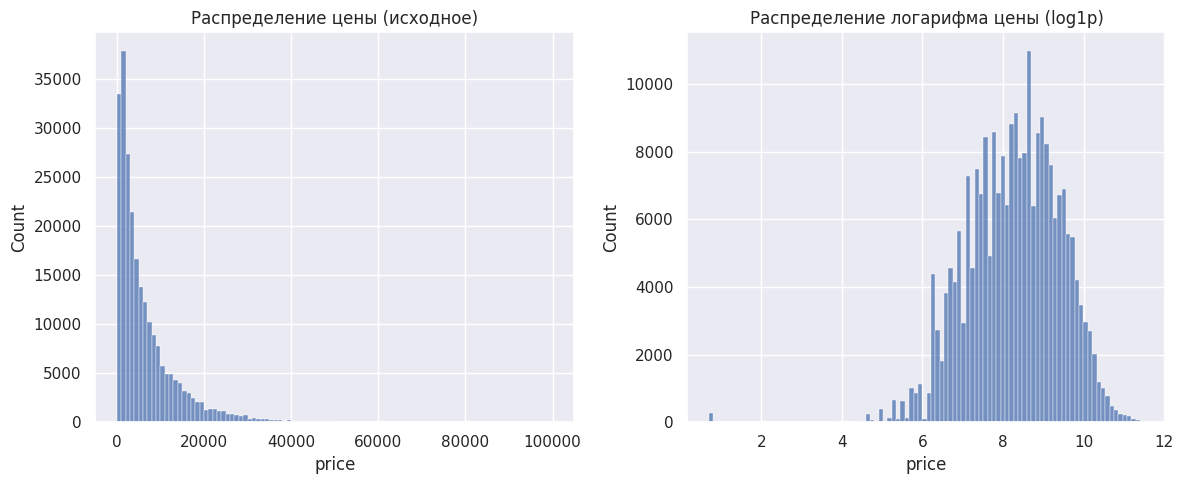

Количество выбросов по цене: 2144
Размер после удаления: (239046, 10)


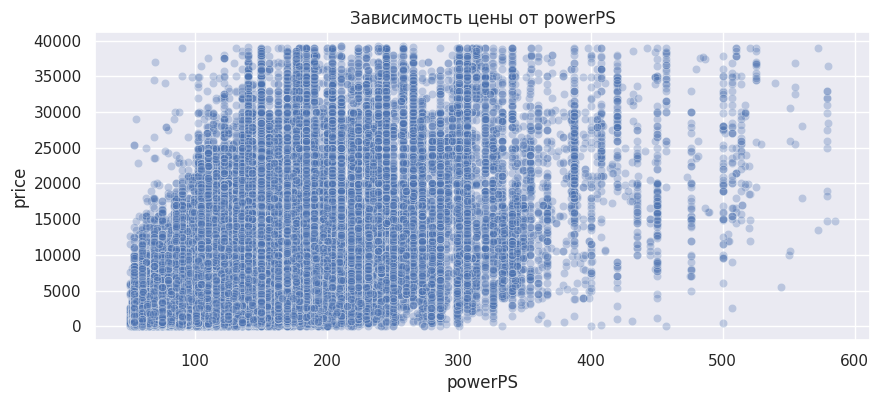

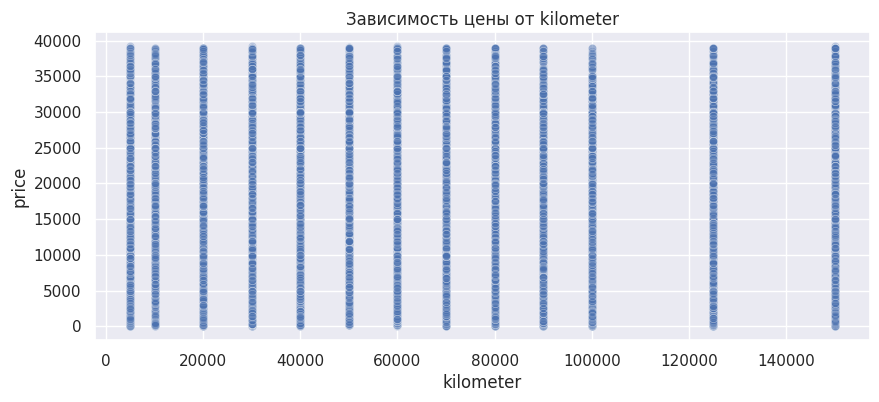

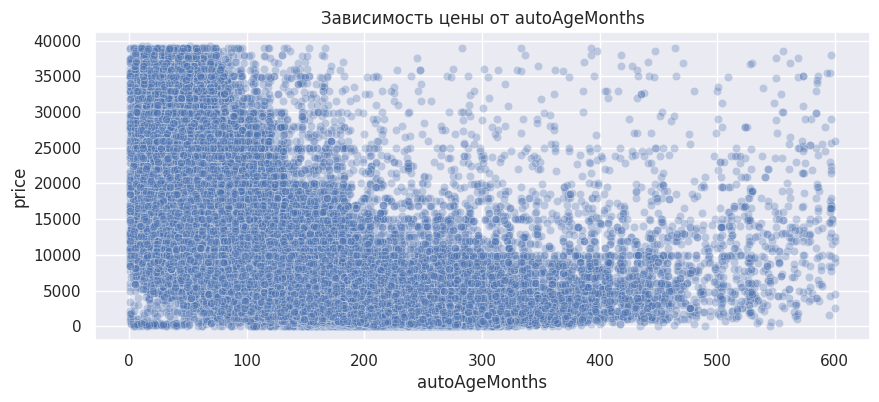

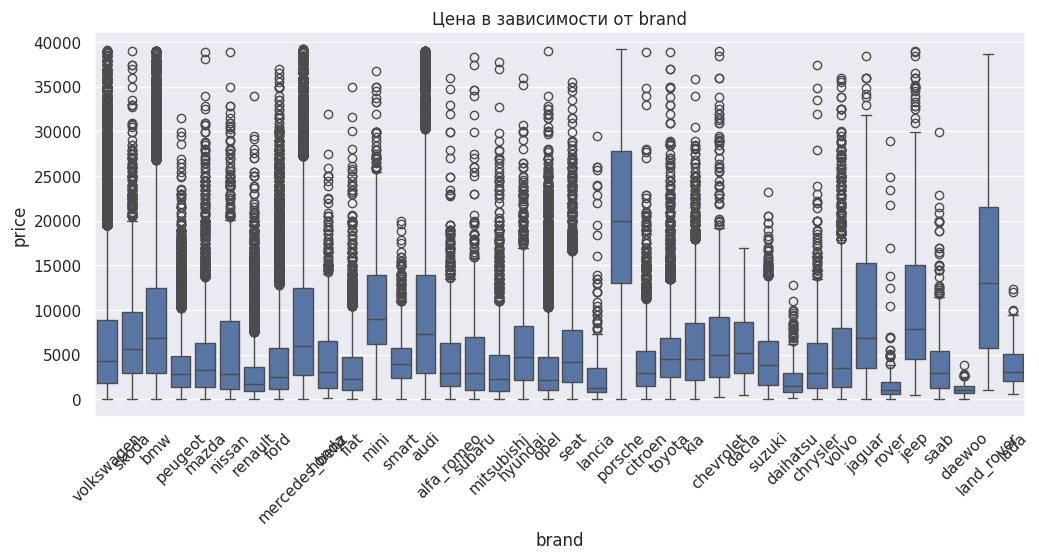

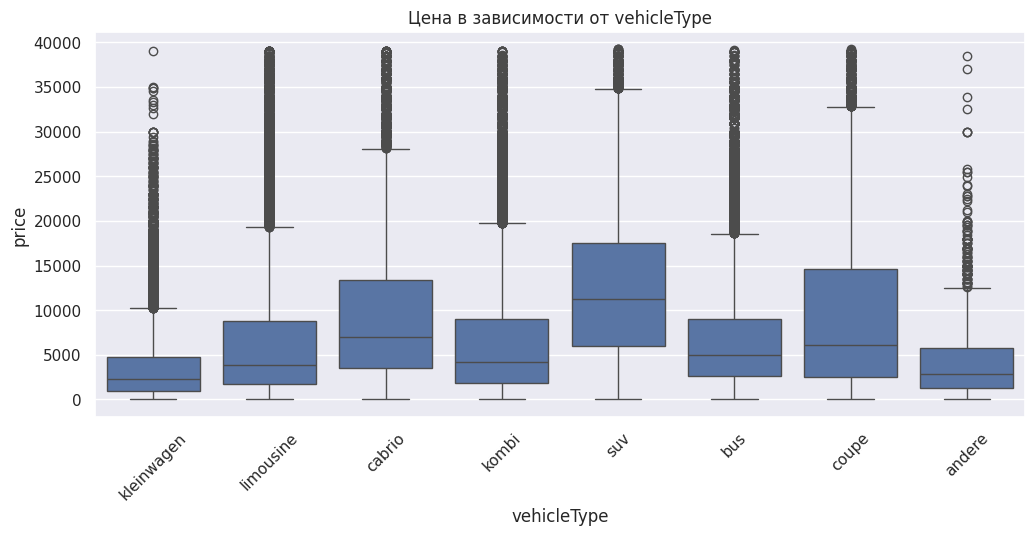

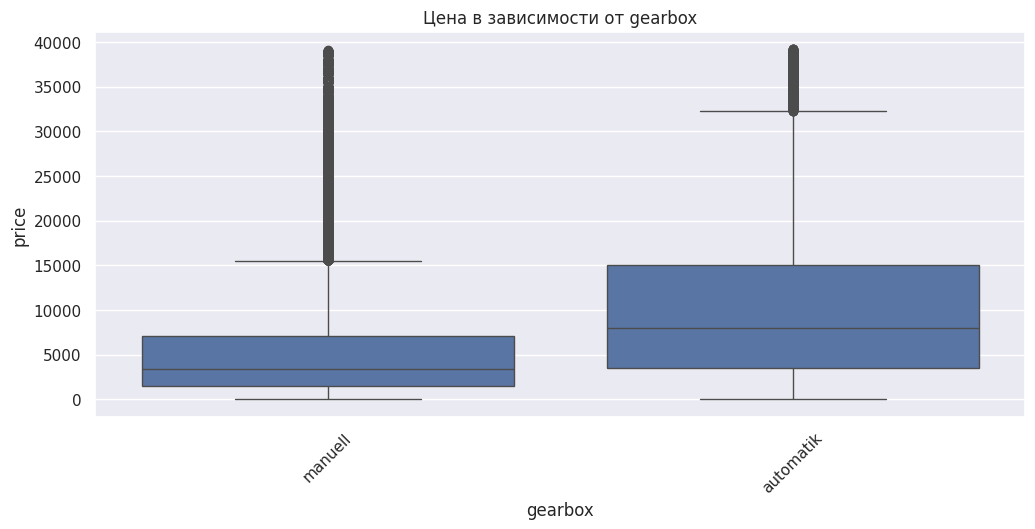

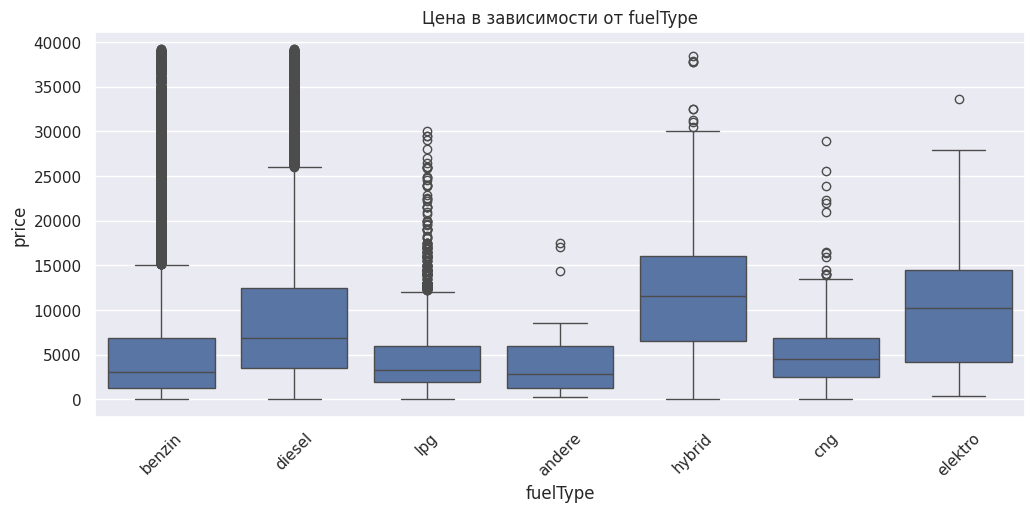

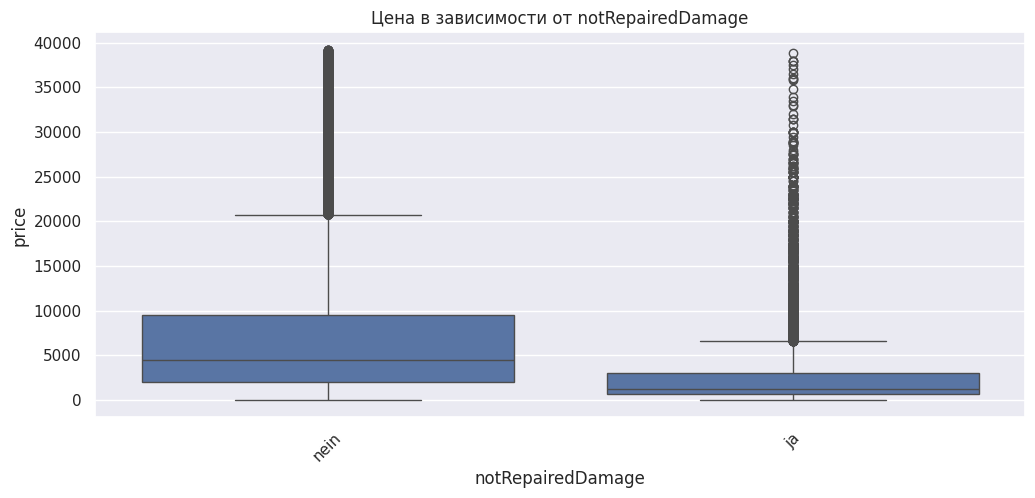

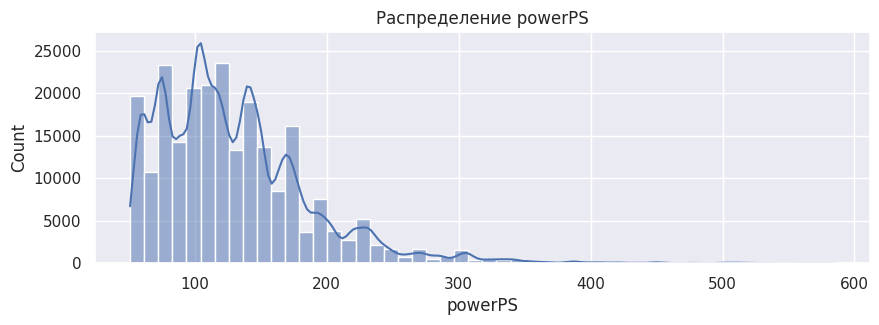

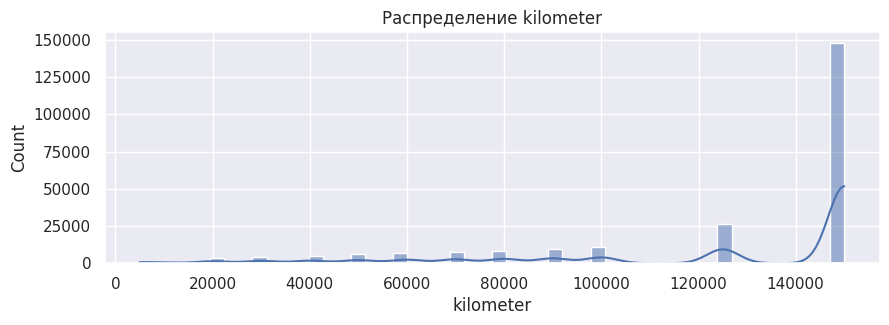

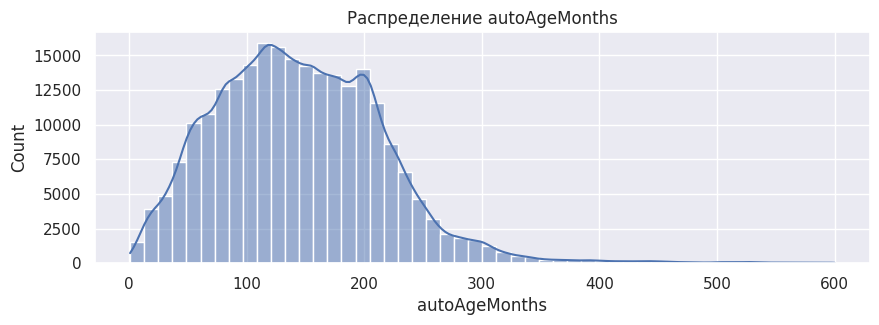

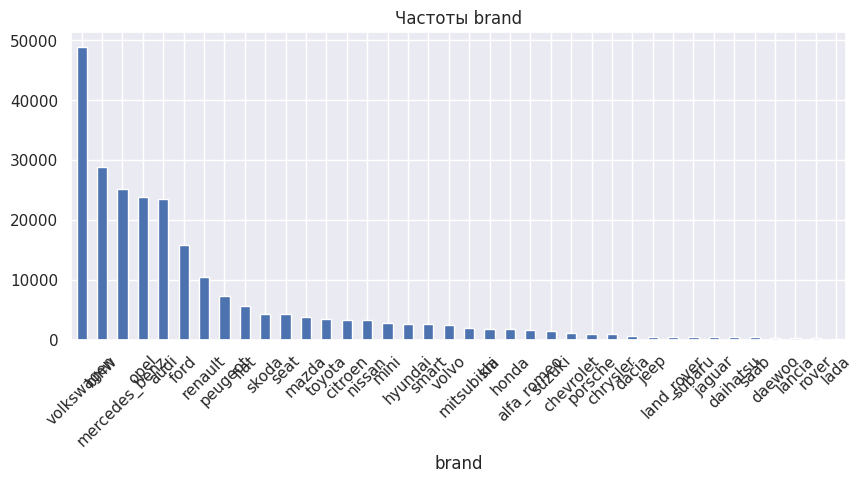

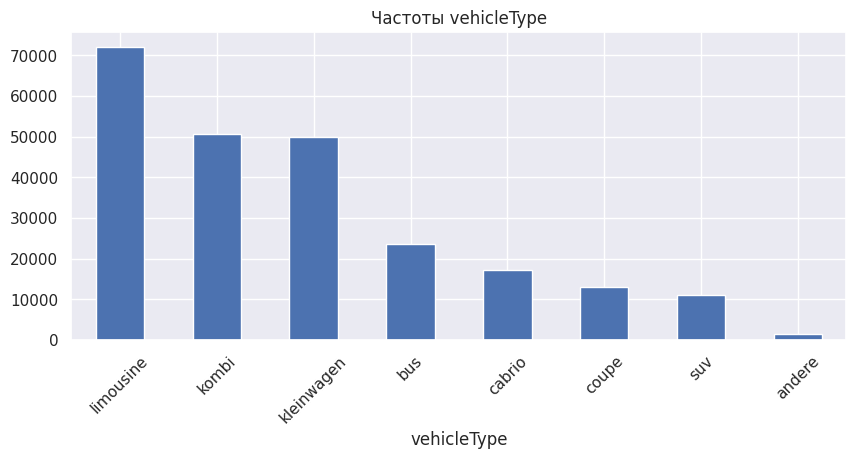

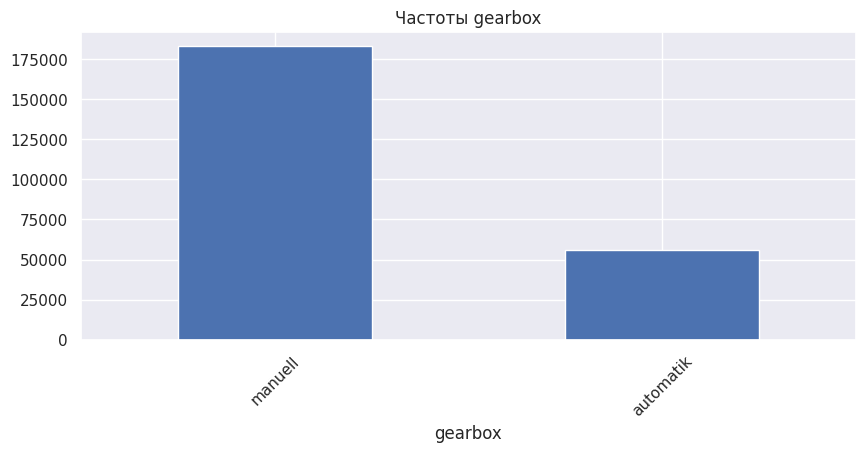

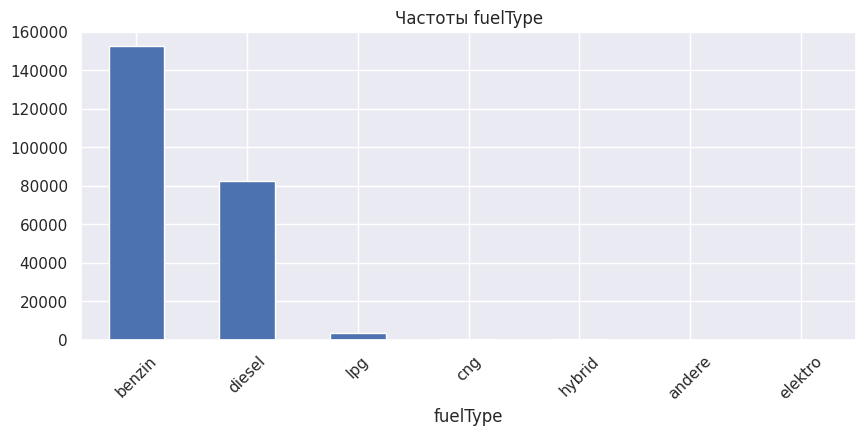

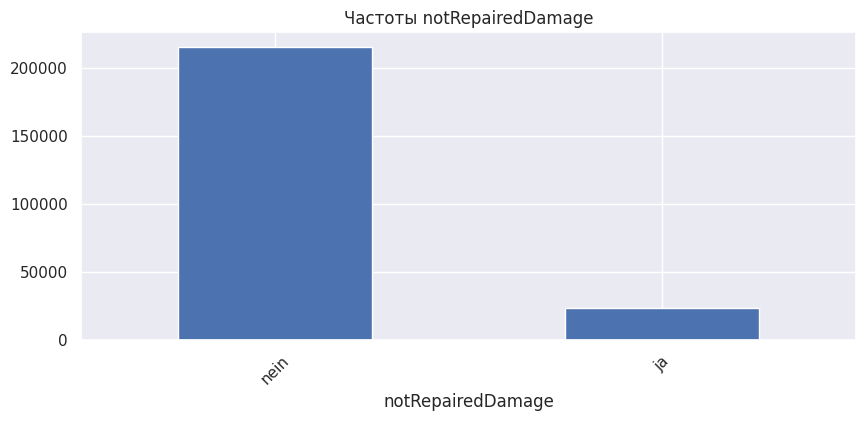

In [17]:
categorical = ['brand', 'model', 'gearbox', 'fuelType', 'notRepairedDamage']
numeric = ['powerPS', 'kilometer', 'autoAgeMonths']
other = []

# YOUR CODE (EDA):
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(data['price'], bins=100, log_scale=False)
plt.title('Распределение цены (исходное)')

plt.subplot(1, 2, 2)
sns.histplot(np.log1p(data['price']), bins=100)
plt.title('Распределение логарифма цены (log1p)')

plt.tight_layout()
plt.show()

Q1 = data['price'].quantile(0.1)
Q3 = data['price'].quantile(0.9)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = data[(data['price'] < lower_bound) | (data['price'] > upper_bound)]
print(f'Количество выбросов по цене: {len(outliers)}')

# Удаление выбросов
data_clean = data[(data['price'] >= lower_bound) & (data['price'] <= upper_bound)]
print(f'Размер после удаления: {data_clean.shape}')

# Вещественные признаки
num_features = ['powerPS', 'kilometer', 'autoAgeMonths']

for col in num_features:
    plt.figure(figsize=(10, 4))
    sns.scatterplot(data=data_clean, x=col, y='price', alpha=0.3)
    plt.title(f'Зависимость цены от {col}')
    plt.show()

# Категориальные признаки
cat_features = ['brand', 'vehicleType', 'gearbox', 'fuelType', 'notRepairedDamage']

for col in cat_features:
    plt.figure(figsize=(12, 5))
    sns.boxplot(data=data_clean, x=col, y='price')
    plt.xticks(rotation=45)
    plt.title(f'Цена в зависимости от {col}')
    plt.show()

for col in num_features:
    plt.figure(figsize=(10, 3))
    sns.histplot(data_clean[col], bins=50, kde=True)
    plt.title(f'Распределение {col}')
    plt.show()

for col in cat_features:
    plt.figure(figsize=(10, 4))
    data_clean[col].value_counts().plot(kind='bar')
    plt.title(f'Частоты {col}')
    plt.xticks(rotation=45)
    plt.show()

In [18]:
data_clean = data_clean[data_clean['autoAgeMonths'] <= 300]

In [19]:
data_clean['bias'] = 1
other += ['bias']

x = data_clean[categorical + numeric + other]
y = data_clean['price']

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler


column_transformer = ColumnTransformer([
    ('ohe', OneHotEncoder(handle_unknown='ignore'), categorical),
    ('scaling', StandardScaler(), numeric),
    ('other',  'passthrough', other)
])

x = column_transformer.fit_transform(x)

In [21]:
# YOUR CODE (data split into train/val/test):
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.2, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)



## Задание 5. Сравнение методов градиентного спуска (2 балла)

В этом задании вам предстоит сравнить методы градиентного спуска на подготовленных вами данных из предыдущего задания.

### Задание 5.1. Подбор оптимальной длины шага (1 балл)

Подберите по валидационной выборке наилучшую длину шага $\lambda$ для каждого метода с точки зрения ошибки. Для этого сделайте перебор по логарифмической сетке. Для каждого метода посчитайте ошибку на обучающей и тестовой выборках, посчитайте качество по метрике $R^2$, сохраните количество итераций до сходимости.

Все параметры кроме `lambda_` стоит выставить равным значениям по умолчанию.

In [22]:
# YOUR CODE:
from sklearn.metrics import r2_score
import scipy.sparse as sp
def tune_lambda(descent_name, train_data, val_data, lambdas, max_iter=300, tol=1e-4, **extra_kwargs):
    """
    Перебор lambda_ по валидационной MSE.
    descent_name : строка, ключ для get_descent ('full', 'stochastic', 'momentum', 'adam').
    extra_kwargs : дополнительные параметры конструктора спуска (например, batch_size).
    """
    X_train, y_train = train_data
    X_val, y_val = val_data
    best_lambda = None
    best_val_loss = np.inf
    best_model = None

    for lam in lambdas:
        print(1)
        # Параметры спуска
        kwargs = extra_kwargs.copy()
        kwargs['dimension'] = X_train.shape[1]
        kwargs['lambda_'] = lam

        config = {
            'descent_name': descent_name,
            'regularized': False,
            'kwargs': kwargs
        }
        print(2)
        # LinearRegression внутри вызывает get_descent(config)
        model = LinearRegression(descent_config=config, tolerance=tol, max_iter=max_iter)
        model.fit(X_train, y_train)
        print(3)
        val_pred = model.predict(X_val)
        val_mse = np.mean((y_val - val_pred) ** 2)
        print(4)
        if val_mse < best_val_loss:
            best_val_loss = val_mse
            best_lambda = lam
            best_model = model

    return best_lambda, best_model


lambdas = np.logspace(-4, 0, 2)   # 10 точек от 0.0001 до 1
methods = {
    'full': 'vanilla',
    'stochastic': 'stochastic',
    'momentum': 'momentum',
    'adam': 'adam'
}

results = {}
for descent_key, method_label in methods.items():
    print(f"Tuning {method_label}...")
    extra = {}
    if descent_key == 'stochastic':
        extra['batch_size'] = 50

    best_lam, best_model = tune_lambda(
        descent_name=descent_key,
        train_data=(X_train, y_train),
        val_data=(X_val, y_val),
        lambdas=lambdas,
        max_iter=300,
        tol=1e-4,
        **extra
    )
    print('OK')

    # Оценка на train/test
    y_train_pred = best_model.predict(X_train)
    y_test_pred = best_model.predict(X_test)

    train_mse = np.mean((y_train - y_train_pred) ** 2)
    test_mse  = np.mean((y_test - y_test_pred) ** 2)
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2  = r2_score(y_test, y_test_pred)

    # Число итераций – из счётчика LearningRate
    iterations = best_model.descent.lr.iteration

    results[method_label] = {
        'best_lambda': best_lam,
        'train_mse': train_mse,
        'test_mse': test_mse,
        'train_r2': train_r2,
        'test_r2': test_r2,
        'iterations': iterations,
        'loss_history': best_model.loss_history
    }
    print(f"  best λ = {best_lam:.4e}, test R² = {test_r2:.4f}, iter = {iterations}")

Tuning vanilla...
1
2
3
4
1
2
3
4
OK
  best λ = 1.0000e+00, test R² = 0.7550, iter = 300
Tuning stochastic...
1
2
3
4
1
2
3
4
OK
  best λ = 1.0000e+00, test R² = -0.7379, iter = 300
Tuning momentum...
1
2
3
4
1
2
3
4
OK
  best λ = 1.0000e+00, test R² = 0.7812, iter = 300
Tuning adam...
1
2
3
4
1
2
3
4
OK
  best λ = 1.0000e+00, test R² = -0.8805, iter = 300


### Задание 5.2. Сравнение методов (1 балла)

Постройте график зависимости ошибки на обучающей выборке от номера итерации (все методы на одном графике).

Посмотрите на получившиеся результаты (таблички с метриками и график). Сравните методы между собой.

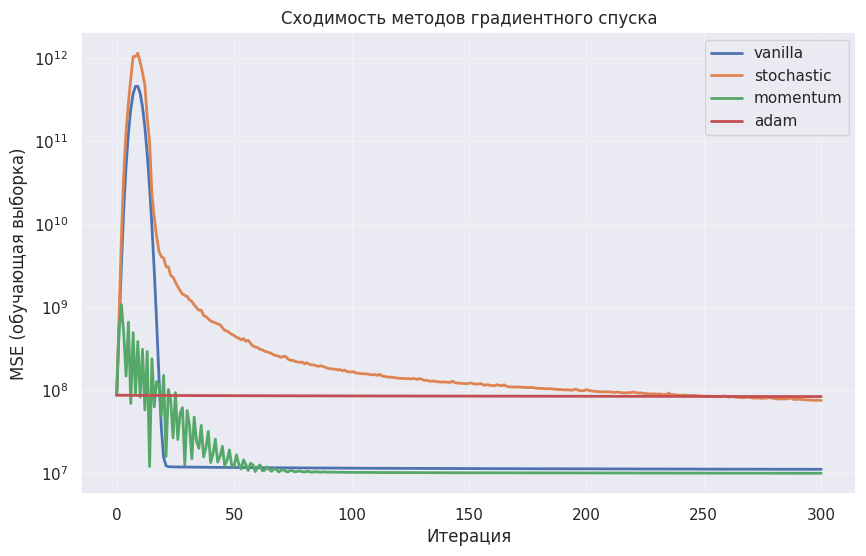

In [23]:
# YOUR CODE:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
for method_name, data in results.items():
    loss_hist = data['loss_history']
    iterations = range(len(loss_hist))
    plt.plot(iterations, loss_hist, label=method_name, linewidth=2)

plt.xlabel('Итерация')
plt.ylabel('MSE (обучающая выборка)')
plt.title('Сходимость методов градиентного спуска')
plt.legend()
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.show()

## Задание 6. Стохастический градиентный спуск и размер батча (1 балл)

В этом задании вам предстоит исследовать влияние размера батча на работу стохастического градиентного спуска.

* Сделайте по несколько запусков (например, k = 10) стохастического градиентного спуска на обучающей выборке для каждого размера батча из перебираемого списка. Замерьте время в секундах и количество итераций до сходимости. Посчитайте среднее этих значений для каждого размера батча.
* Постройте график зависимости количества шагов до сходимости от размера батча. _(под сходимостью понимается достижение критерия останова)_
* Постройте график зависимости времени до сходимости от размера батча.

Посмотрите на получившиеся результаты. Какие выводы можно сделать про подбор размера батча для стохастического градиентного спуска?

In [25]:
batch_sizes = np.arange(5, 500, 10)

# YOUR CODE:
import time
import numpy as np
import matplotlib.pyplot as plt
from linear_regression import LinearRegression

lambda_ = results['stochastic']['best_lambda']

k = 10
tolerance = 1e-4
max_iter  = 500
dimension = X_train.shape[1]

mean_iters, mean_times = [], []
std_iters,  std_times  = [], []

for batch_size in batch_sizes:
    iters_list, times_list = [], []
    for _ in range(k):
        config = {
            'descent_name': 'stochastic',
            'kwargs': {
                'dimension':  dimension,
                'batch_size': int(batch_size),
                'lambda_':    lambda_,
            },
        }
        model = LinearRegression(descent_config=config,
                                 tolerance=tolerance, max_iter=max_iter)

        t0 = time.perf_counter()
        model.fit(X_train, y_train)
        elapsed = time.perf_counter() - t0

        iters_list.append(len(model.loss_history) - 1)
        times_list.append(elapsed)

    mean_iters.append(np.mean(iters_list))
    mean_times.append(np.mean(times_list))
    std_iters.append(np.std(iters_list))
    std_times.append(np.std(times_list))

    print(f"batch={batch_size:3d} | iters={np.mean(iters_list):6.1f}±{np.std(iters_list):4.1f} "
          f"| time={np.mean(times_list):.3f}s±{np.std(times_list):.3f}s")

batch=  5 | iters= 500.0± 0.0 | time=13.087s±1.596s
batch= 15 | iters= 500.0± 0.0 | time=12.736s±0.438s
batch= 25 | iters= 500.0± 0.0 | time=12.998s±0.953s
batch= 35 | iters= 500.0± 0.0 | time=13.685s±1.048s
batch= 45 | iters= 500.0± 0.0 | time=14.095s±1.281s
batch= 55 | iters= 500.0± 0.0 | time=12.448s±0.323s
batch= 65 | iters= 500.0± 0.0 | time=12.515s±0.629s
batch= 75 | iters= 500.0± 0.0 | time=13.733s±1.531s
batch= 85 | iters= 500.0± 0.0 | time=14.735s±1.846s
batch= 95 | iters= 500.0± 0.0 | time=14.339s±0.865s
batch=105 | iters= 500.0± 0.0 | time=13.762s±0.469s
batch=115 | iters= 500.0± 0.0 | time=13.309s±0.338s
batch=125 | iters= 500.0± 0.0 | time=13.959s±0.442s
batch=135 | iters= 500.0± 0.0 | time=14.174s±0.456s
batch=145 | iters= 500.0± 0.0 | time=13.655s±0.520s
batch=155 | iters= 500.0± 0.0 | time=14.076s±0.426s
batch=165 | iters= 500.0± 0.0 | time=13.338s±0.628s
batch=175 | iters= 500.0± 0.0 | time=13.359s±0.407s
batch=185 | iters= 500.0± 0.0 | time=13.542s±0.369s
batch=195 | 

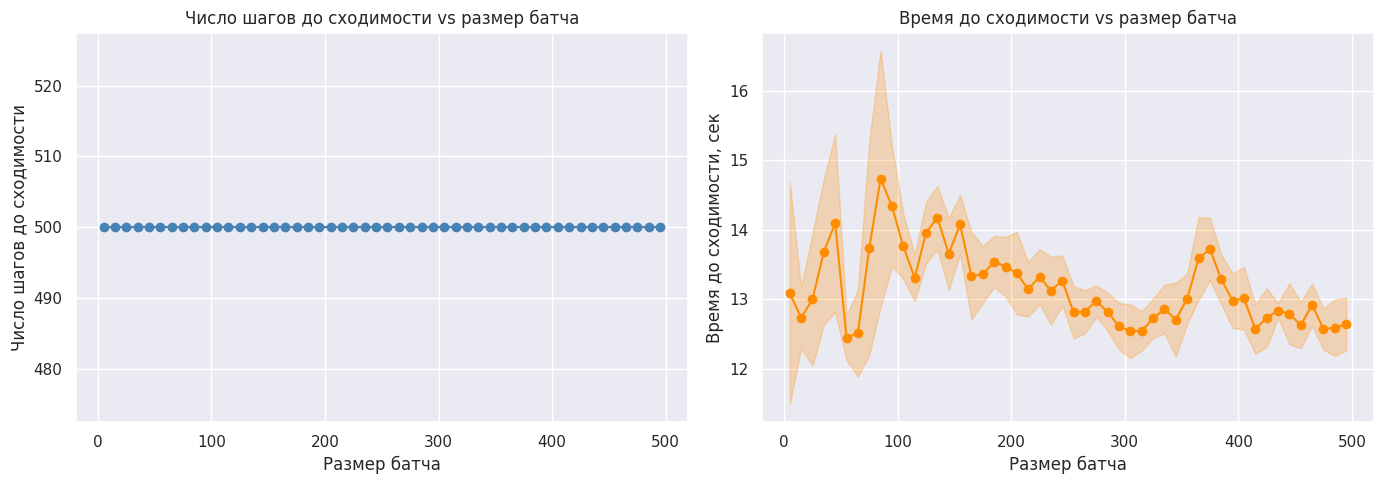

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# --- конвертация результатов в numpy ---
batch_sizes = np.asarray(batch_sizes, dtype=float)
mean_iters  = np.asarray(mean_iters,  dtype=float)
mean_times  = np.asarray(mean_times,  dtype=float)
std_iters   = np.asarray(std_iters,   dtype=float)
std_times   = np.asarray(std_times,   dtype=float)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- число шагов до сходимости ---
axes[0].plot(batch_sizes, mean_iters, 'o-', color='steelblue', label='mean')
axes[0].fill_between(batch_sizes,
                     mean_iters - std_iters,
                     mean_iters + std_iters,
                     alpha=0.25, color='steelblue')
axes[0].set_xlabel('Размер батча')
axes[0].set_ylabel('Число шагов до сходимости')
axes[0].set_title('Число шагов до сходимости vs размер батча')
axes[0].grid(True)

# --- время до сходимости ---
axes[1].plot(batch_sizes, mean_times, 'o-', color='darkorange', label='mean')
axes[1].fill_between(batch_sizes,
                     np.maximum(mean_times - std_times, 0),
                     mean_times + std_times,
                     alpha=0.25, color='darkorange')
axes[1].set_xlabel('Размер батча')
axes[1].set_ylabel('Время до сходимости, сек')
axes[1].set_title('Время до сходимости vs размер батча')
axes[1].grid(True)

plt.tight_layout()
plt.show()